In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

from sklearn.neighbors import NearestNeighbors

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
df = pd.read_csv('E-commerce_Customer_Segmentation_2026.csv')

print(df.head())

   customer_id customer_segment     segment_category  age age_group  gender  \
0  CUST-000001         Consumer  High Value Inactive   70       65+    Male   
1  CUST-000002          Premium  High Value Inactive   53     45-54  Female   
2  CUST-000003         Consumer  High Value Inactive   82       65+    Male   
3  CUST-000004       Enterprise    High Value Active   18     18-24    Male   
4  CUST-000005          Premium    High Value Active   64     55-64    Male   

                country       city income_bracket education_level  ...  \
0                Canada   Winnipeg          150K+    Professional  ...   
1               Germany      Essen        25K-50K     High School  ...   
2                Mexico     Puebla       75K-100K       Bachelors  ...   
3             Singapore  Singapore          150K+         Masters  ...   
4  United Arab Emirates   Fujairah          150K+             PhD  ...   

  customer_value_category activity_status  health_status  churn_risk_category  \

In [ ]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

Shape: (50000, 53)

Columns:
Index(['customer_id', 'customer_segment', 'segment_category', 'age',
       'age_group', 'gender', 'country', 'city', 'income_bracket',
       'education_level', 'employment_type', 'marital_status', 'tenure_months',
       'total_purchases', 'avg_order_value_usd', 'total_spent_usd',
       'purchase_frequency', 'days_since_last_purchase',
       'preferred_category_1', 'preferred_category_2', 'preferred_category_3',
       'shopping_channel', 'device_used', 'payment_method', 'return_count',
       'complaint_count', 'satisfaction_score', 'satisfaction_level',
       'loyalty_tier', 'email_open_rate', 'click_through_rate',
       'conversion_rate', 'social_media_presence',
       'customer_lifetime_value_usd', 'customer_acquisition_cost_usd',
       'customer_profitability_usd', 'recency_score', 'frequency_score',
       'monetary_score', 'rfm_score', 'churn_risk_score',
       'customer_health_score', 'dataset_year', 'customer_value_category',
       'activ

In [ ]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values:
customer_id                          0
customer_segment                     0
segment_category                     0
age                                  0
age_group                            0
gender                               0
country                              0
city                                 0
income_bracket                       0
education_level                      0
employment_type                      0
marital_status                       0
tenure_months                        0
total_purchases                      0
avg_order_value_usd                  0
total_spent_usd                      0
purchase_frequency                   0
days_since_last_purchase             0
preferred_category_1                 0
preferred_category_2             16743
preferred_category_3             33257
shopping_channel                     0
device_used                          0
payment_method                       0
return_count                         0
complaint

In [ ]:
rfm = df[['customer_id',
          'days_since_last_purchase',
          'total_purchases',
          'total_spent_usd']].copy()

rfm.columns = ['CustomerID',
               'Recency',
               'Frequency',
               'Monetary']

print(rfm.head())

    CustomerID  Recency  Frequency   Monetary
0  CUST-000001       63         28   25552.80
1  CUST-000002      342         75   22564.50
2  CUST-000003       64        163  108217.33
3  CUST-000004        2        192  117811.20
4  CUST-000005        4         31   20201.15


In [ ]:
print(rfm.describe())

            Recency     Frequency       Monetary
count  50000.000000  50000.000000   50000.000000
mean      62.971240     99.418460   50266.546156
std       93.281404     57.780178   44071.209164
min        0.000000      0.000000       0.000000
25%        2.000000     49.000000   13893.577500
50%       19.000000     99.000000   37541.625000
75%       77.000000    150.000000   76811.242500
max      365.000000    199.000000  198574.140000


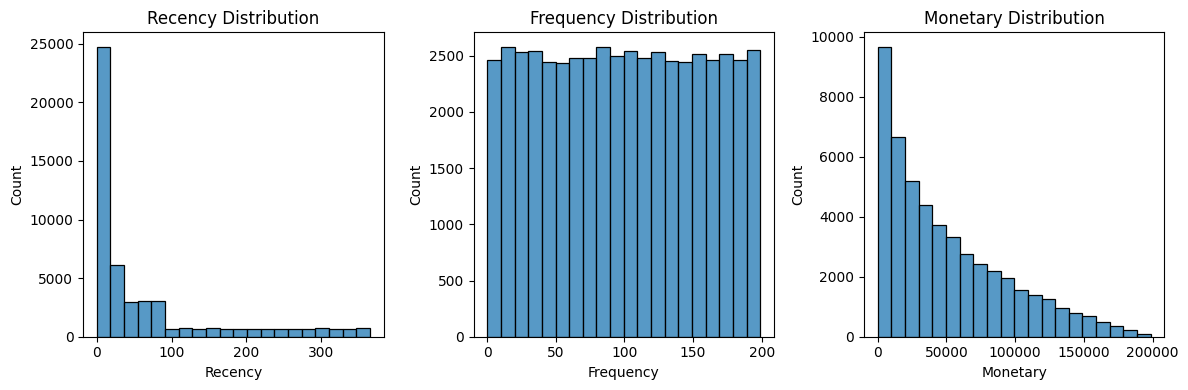

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
sns.histplot(rfm['Recency'], bins=20)
plt.title('Recency Distribution')

plt.subplot(1, 3, 2)
sns.histplot(rfm['Frequency'], bins=20)
plt.title('Frequency Distribution')

plt.subplot(1, 3, 3)
sns.histplot(rfm['Monetary'], bins=20)
plt.title('Monetary Distribution')

plt.tight_layout()
plt.show()

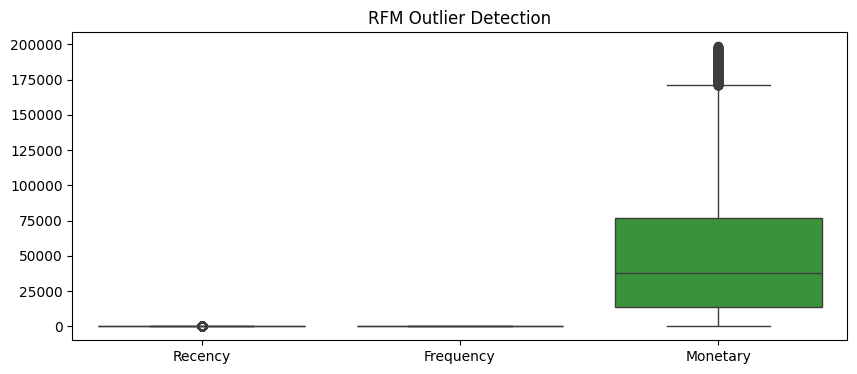

In [ ]:
plt.figure(figsize=(10, 4))

sns.boxplot(data=rfm[['Recency',
                      'Frequency',
                      'Monetary']])

plt.title("RFM Outlier Detection")
plt.show()

In [ ]:
X = rfm[['Recency',
         'Frequency',
         'Monetary']]

print(X.head())

   Recency  Frequency   Monetary
0       63         28   25552.80
1      342         75   22564.50
2       64        163  108217.33
3        2        192  117811.20
4        4         31   20201.15


In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[ 3.08317481e-04 -1.23604974e+00 -5.60774115e-01]
 [ 2.99128805e+00 -4.22613863e-01 -6.28580965e-01]
 [ 1.10286750e-02  1.10041502e+00  1.31494834e+00]
 [-6.53633488e-01  1.60232227e+00  1.53264071e+00]
 [-6.32192773e-01 -1.18412831e+00 -6.82207214e-01]]


In [ ]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original Shape:", X_scaled.shape)
print("New Shape:", X_pca.shape)

print("Explained Variance:",
      pca.explained_variance_ratio_)

print("Total Variance:",
      sum(pca.explained_variance_ratio_))

Original Shape: (50000, 3)
New Shape: (50000, 2)
Explained Variance: [0.55555285 0.333314  ]
Total Variance: 0.8888668448338476


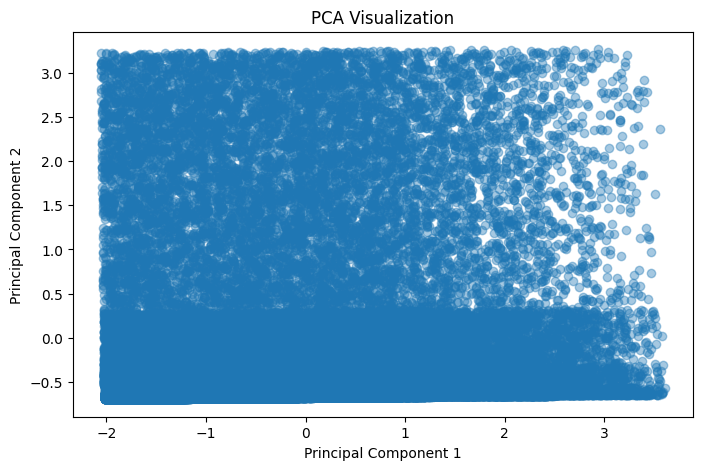

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(X_pca[:, 0],
            X_pca[:, 1],
            alpha=0.4)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("PCA Visualization")
plt.show()

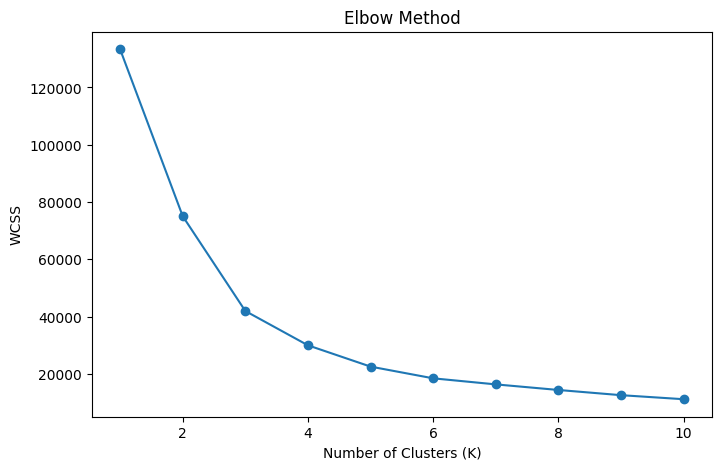

In [ ]:
wcss = []

for k in range(1, 11):

    model = KMeans(n_clusters=k,
                   random_state=42,
                   n_init=10)

    model.fit(X_pca)

    wcss.append(model.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker='o')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")

plt.title("Elbow Method")
plt.show()

In [23]:
scores = []

for k in range(2, 9):

    model = KMeans(n_clusters=k,
                   random_state=42,
                   n_init=10)

    labels = model.fit_predict(X_pca)

    score = silhouette_score(X_pca, labels)

    scores.append(score)

    print("K =", k, "Score =", score)

best_k = range(2, 9)[np.argmax(scores)]

print("\nBest K:", best_k)

K = 2 Score = 0.42507481828427796
K = 3 Score = 0.4991110752801051
K = 4 Score = 0.4523473685543369
K = 5 Score = 0.46284262871618675
K = 6 Score = 0.4202002583695975
K = 7 Score = 0.423904666327589
K = 8 Score = 0.39466919976292003

Best K: 3


In [24]:
kmeans = KMeans(n_clusters=best_k,
                random_state=42,
                n_init=10)

rfm['KMeans_Cluster'] = kmeans.fit_predict(X_pca)

print(rfm.head())

    CustomerID  Recency  Frequency   Monetary  KMeans_Cluster
0  CUST-000001       63         28   25552.80               1
1  CUST-000002      342         75   22564.50               2
2  CUST-000003       64        163  108217.33               0
3  CUST-000004        2        192  117811.20               0
4  CUST-000005        4         31   20201.15               1


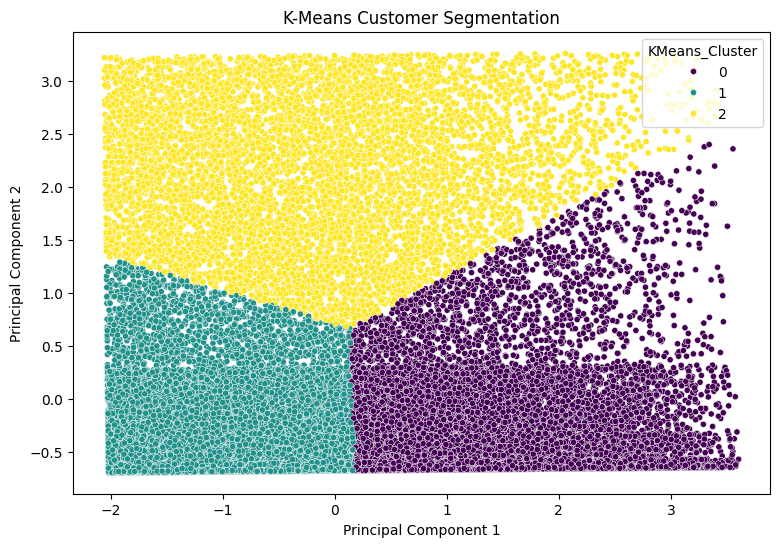

In [25]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=rfm['KMeans_Cluster'],
    palette='viridis',
    s=20
)

plt.title("K-Means Customer Segmentation")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.show()

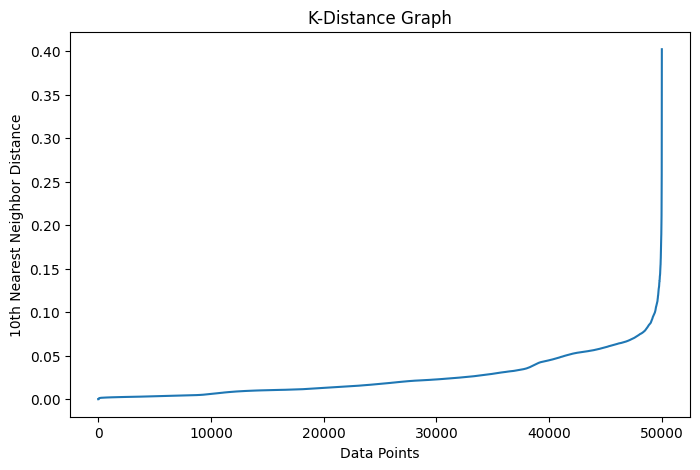

In [26]:
neighbors = NearestNeighbors(n_neighbors=10)

neighbors.fit(X_pca)

distances, indices = neighbors.kneighbors(X_pca)

distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 5))

plt.plot(distances)

plt.xlabel("Data Points")
plt.ylabel("10th Nearest Neighbor Distance")

plt.title("K-Distance Graph")

plt.show()

In [27]:
dbscan = DBSCAN(eps=0.5,
                min_samples=10)

rfm['DBSCAN_Cluster'] = dbscan.fit_predict(X_pca)

print(rfm['DBSCAN_Cluster'].value_counts())

DBSCAN_Cluster
0    50000
Name: count, dtype: int64


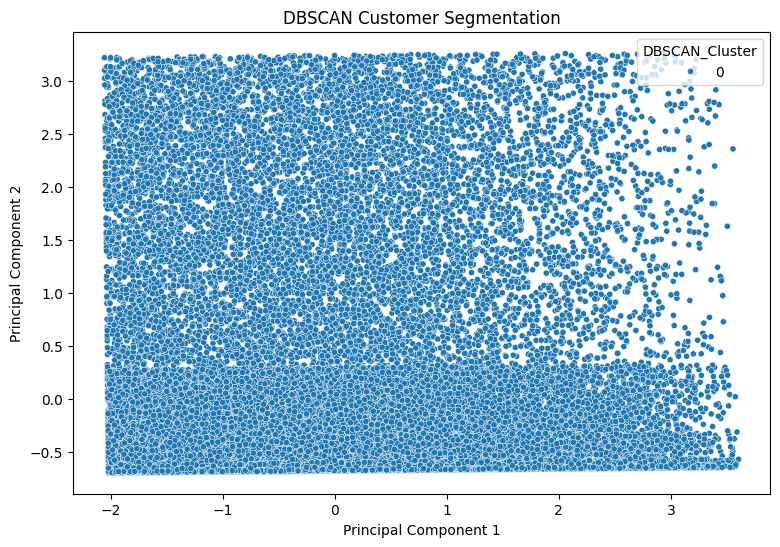

In [28]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=rfm['DBSCAN_Cluster'],
    palette='tab10',
    s=20
)

plt.title("DBSCAN Customer Segmentation")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.show()

In [29]:
print("K-Means Clusters:")
print(rfm['KMeans_Cluster'].value_counts())

print("\nDBSCAN Clusters:")
print(rfm['DBSCAN_Cluster'].value_counts())

print("\nK-Means Silhouette:",
      silhouette_score(X_pca,
                       rfm['KMeans_Cluster']))

db_labels = rfm['DBSCAN_Cluster']

if len(set(db_labels) - {-1}) > 1:

    mask = db_labels != -1

    print("DBSCAN Silhouette:",
          silhouette_score(
              X_pca[mask],
              db_labels[mask]
          ))
else:
    print("DBSCAN Silhouette cannot be calculated meaningfully.")

K-Means Clusters:
KMeans_Cluster
1    24133
0    18597
2     7270
Name: count, dtype: int64

DBSCAN Clusters:
DBSCAN_Cluster
0    50000
Name: count, dtype: int64

K-Means Silhouette: 0.4991110752801051
DBSCAN Silhouette cannot be calculated meaningfully.


In [31]:
sample = rfm.sample(n=5000, random_state=42)

X_sample = X_scaled[sample.index]

tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42,
    init='pca',
    learning_rate='auto'
)

X_tsne = tsne.fit_transform(X_sample)

print("t-SNE Shape:", X_tsne.shape)

t-SNE Shape: (5000, 2)


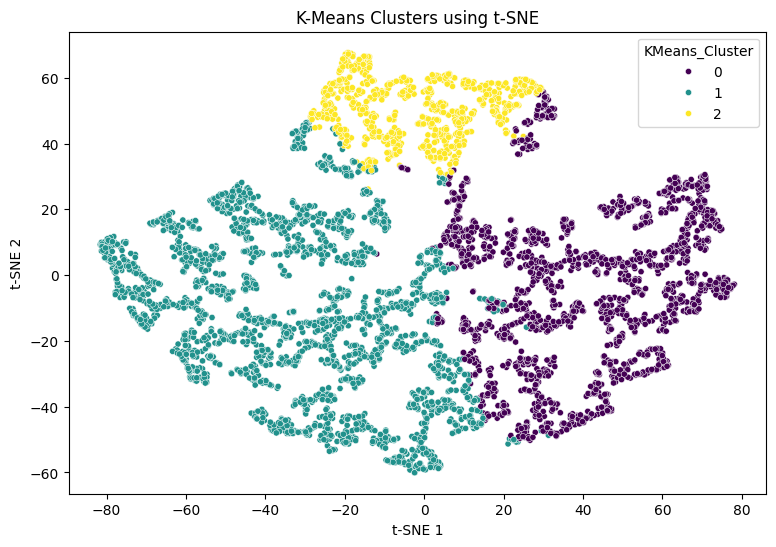

In [32]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_tsne[:, 0],
    y=X_tsne[:, 1],
    hue=sample['KMeans_Cluster'],
    palette='viridis',
    s=20
)

plt.title("K-Means Clusters using t-SNE")

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")

plt.show()

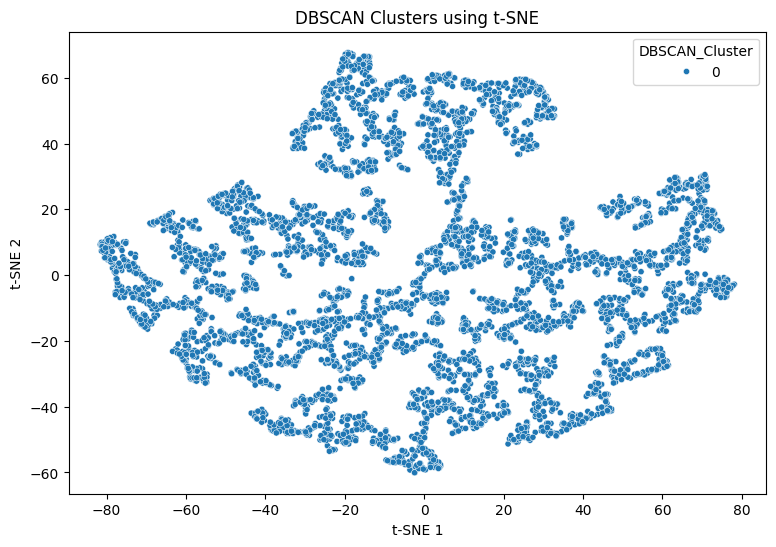

In [34]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_tsne[:, 0],
    y=X_tsne[:, 1],
    hue=sample['DBSCAN_Cluster'],
    palette='tab10',
    s=20
)

plt.title("DBSCAN Clusters using t-SNE")

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")

plt.show()

In [35]:
cluster_summary = rfm.groupby(
    'KMeans_Cluster'
)[['Recency', 'Frequency', 'Monetary']].mean()

print(cluster_summary.round(2))

                Recency  Frequency  Monetary
KMeans_Cluster                              
0                 31.18     152.86  89011.74
1                 26.98      59.29  21985.52
2                263.78      95.90  45034.32


In [36]:
median_r = rfm['Recency'].median()
median_f = rfm['Frequency'].median()
median_m = rfm['Monetary'].median()

def get_persona(row):

    if (row['Recency'] <= median_r
        and row['Frequency'] >= median_f
        and row['Monetary'] >= median_m):

        return "Champions"

    elif (row['Recency'] > median_r
          and row['Frequency'] >= median_f):

        return "At-Risk Customers"

    elif row['Monetary'] >= median_m:

        return "Big Spenders"

    elif row['Recency'] <= median_r:

        return "Potential Loyalists"

    else:

        return "Low Engagement Customers"


personas = cluster_summary.apply(
    get_persona, axis=1
)

print(personas)

KMeans_Cluster
0           At-Risk Customers
1    Low Engagement Customers
2                Big Spenders
dtype: object


In [37]:
rfm['Persona'] = rfm['KMeans_Cluster'].map(personas)

print(rfm.head(10))

    CustomerID  Recency  Frequency   Monetary  KMeans_Cluster  DBSCAN_Cluster  \
0  CUST-000001       63         28   25552.80               1               0   
1  CUST-000002      342         75   22564.50               2               0   
2  CUST-000003       64        163  108217.33               0               0   
3  CUST-000004        2        192  117811.20               0               0   
4  CUST-000005        4         31   20201.15               1               0   
5  CUST-000006        2        111   47008.50               1               0   
6  CUST-000007        0         59   50410.78               1               0   
7  CUST-000008       13         94   55169.54               1               0   
8  CUST-000009       18        132   46007.28               0               0   
9  CUST-000010      103         67   34754.91               1               0   

                    Persona  
0  Low Engagement Customers  
1              Big Spenders  
2         At-Risk 

Persona
Low Engagement Customers    24133
At-Risk Customers           18597
Big Spenders                 7270
Name: count, dtype: int64


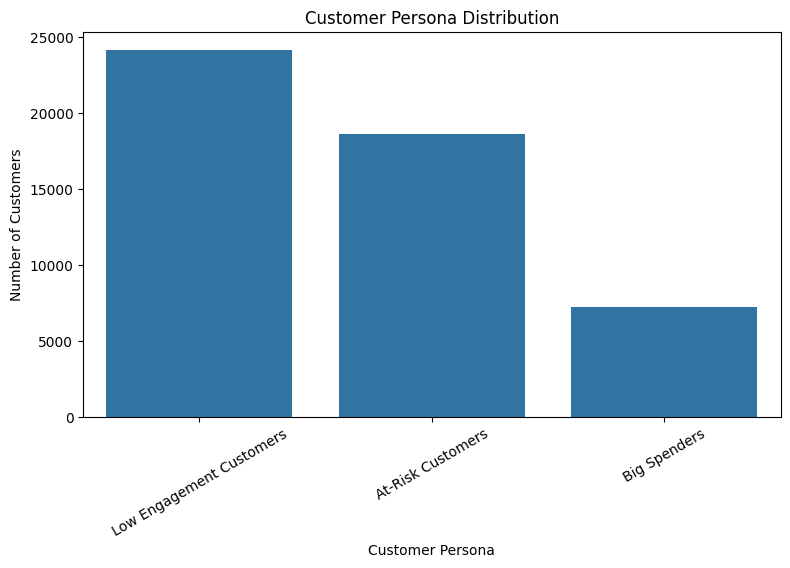

In [38]:
print(rfm['Persona'].value_counts())

plt.figure(figsize=(9, 5))

sns.countplot(
    data=rfm,
    x='Persona',
    order=rfm['Persona'].value_counts().index
)

plt.title("Customer Persona Distribution")
plt.xlabel("Customer Persona")
plt.ylabel("Number of Customers")

plt.xticks(rotation=30)

plt.show()

In [39]:
rfm.to_csv(
    'Customer_Segmentation_Results.csv',
    index=False
)

print("Final dataset saved successfully!")

Final dataset saved successfully!


In [40]:
from google.colab import files

files.download('Customer_Segmentation_Results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>